# 09 · Why coupling beats Gaussian theory: testing the tail-cancellation mechanism

**Claim to test.** Notebook 07 found that the coupled latency detector is 6–19× faster than per-slice CUSUM on small slice-local faults. Gaussian first-order theory predicts only about 2×. The proposed explanation, from our own analysis and repeated by the external literature review, has two parts:

1. **Common factor.** Slice latencies share a bursty, heavy-tailed *common* factor: eMBB bursts and capacity dips slow every slice at once.
2. **Cancellation.** The coupled filter $\Sigma^{-1}$ removes that common factor and, with it, the heavy tail. Its CUSUM therefore needs a much lower threshold for the same false-alarm rate. The speed-up should then factor as

$$\text{speed-up} \approx \underbrace{\frac{h_\text{per-slice}}{h_\text{coupled}}}_{\text{threshold factor}} \times \underbrace{\frac{\mu_\text{coupled}}{\mu_\text{per-slice}}}_{\text{drift factor}},$$

where $h$ is the threshold at a common ARL and $\mu$ the post-fault drift of the CUSUM increment, since delay ≈ $h/\mu$.

**Tests.**
- **T1:** Is the common mode heavy-tailed, and is the cancelled residual light-tailed?
- **T2:** How inflated is each statistic's threshold relative to Gaussian theory?
- **T3:** Does threshold factor × drift factor reproduce the measured speed-up?
- **T4 (control):** Run the same detectors on *Gaussian* data with the same correlation $\Sigma$ and the same fault shifts. If the mechanism is right, the speed-up there falls back towards the Gaussian prediction.

To isolate the mechanism, every comparison uses **one stream and one direction**. That is a one-sided CUSUM ($k = 0.5$) on slice $j$'s whitened latency $z_j$, against the same CUSUM on its regression-adjusted residual $r_j = (\Sigma^{-1}z)_j / \sqrt{(\Sigma^{-1})_{jj}}$, Hawkins' variable. $r_j$ is exactly the bank's "slice $j$ alone" candidate. Both are calibrated to ARL 1000 windows (100 s).

**Run it** from the project root (about 4 minutes):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/09_tail_cancellation.ipynb
```

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import CUSUMBank, StreamModel, stream_array
from slicead.eval import calibrate_threshold, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-08
OUT = Path("../results/09_tail_cancellation")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"09_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"09_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"09_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
LAT = [(s, "latency_ms") for s in SLICES]
TARGET_ARL = 1000

t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
model = StreamModel().fit(stream_array(train, LAT))
Ztr = model.whiten(stream_array(train, LAT))
Sigma = np.corrcoef(Ztr.reshape(-1, 3).T)
Si = np.linalg.inv(Sigma)
ADJ = Si / np.sqrt(np.diag(Si))          # r = z @ ADJ : regression-adjusted residuals (unit variance)

def residuals(Z):
    return Z @ ADJ

Zcal = model.whiten(stream_array(calib, LAT))
Rcal = residuals(Zcal)
print(f"simulated in {time.time() - t0:.0f} s; fault-free correlation of whitened latencies:")
print(np.round(Sigma, 2))

simulated in 63 s; fault-free correlation of whitened latencies:
[[1.   0.42 0.5 ]
 [0.42 1.   0.72]
 [0.5  0.72 1.  ]]


## T1. Is there a heavy-tailed common factor, and does $\Sigma^{-1}$ remove it?

Split the fault-free whitened latency vector into its **common mode**, the projection onto the leading eigenvector of $\Sigma$, and the **rest**. For each piece, and for each slice's $z_j$ against its residual $r_j$, measure the tail: excess kurtosis (0 for a Gaussian), skewness, and the 99.9% quantile in standard deviations (3.09 for a Gaussian).

In [2]:
def tail_stats(x):
    x = (x - x.mean()) / x.std()
    return dict(excess_kurtosis=stats.kurtosis(x), skewness=stats.skew(x), q999=np.quantile(x, 0.999))

w, V = np.linalg.eigh(Sigma)
v1 = V[:, -1] * np.sign(V[:, -1].sum())
flat = Zcal.reshape(-1, 3)
common = flat @ v1
rest = flat - np.outer(common, v1)
rows = [dict(series="common mode (leading eigenvector)", share_of_variance=w[-1] / w.sum(), **tail_stats(common)),
        dict(series="rest (orthogonal complement), 2nd axis", share_of_variance=w[-2] / w.sum(), **tail_stats(flat @ V[:, -2])),
        dict(series="rest (orthogonal complement), 3rd axis", share_of_variance=w[-3] / w.sum(), **tail_stats(flat @ V[:, -3]))]
for j, s in enumerate(SLICES):
    rows.append(dict(series=f"{s}: whitened latency z", **tail_stats(flat[:, j])))
    rows.append(dict(series=f"{s}: regression residual r", **tail_stats(Rcal.reshape(-1, 3)[:, j])))
rows.append(dict(series="Gaussian reference", excess_kurtosis=0.0, skewness=0.0, q999=stats.norm.ppf(0.999)))
tails = pd.DataFrame(rows)
print("leading eigenvector (eMBB, URLLC, mMTC):", np.round(v1, 2))
tails.round(2)

leading eigenvector (eMBB, URLLC, mMTC): [0.51 0.6  0.62]


,series,share_of_variance,excess_kurtosis,skewness,q999
0,common mode (leading eigenvector),0.70,0.66,0.21,3.61
1,"rest (orthogonal complement), 2nd axis",0.21,3.67,0.77,5.10
2,"rest (orthogonal complement), 3rd axis",0.09,0.16,-0.07,3.08
3,eMBB: whitened latency z,NaN,5.53,-0.47,4.01
4,eMBB: regression residual r,NaN,5.69,-0.74,3.87
5,URLLC: whitened latency z,NaN,0.27,0.30,3.63
6,URLLC: regression residual r,NaN,0.20,0.19,3.48
7,mMTC: whitened latency z,NaN,0.31,0.25,3.59
8,mMTC: regression residual r,NaN,0.16,0.09,3.29
9,Gaussian reference,NaN,0.00,0.00,3.09


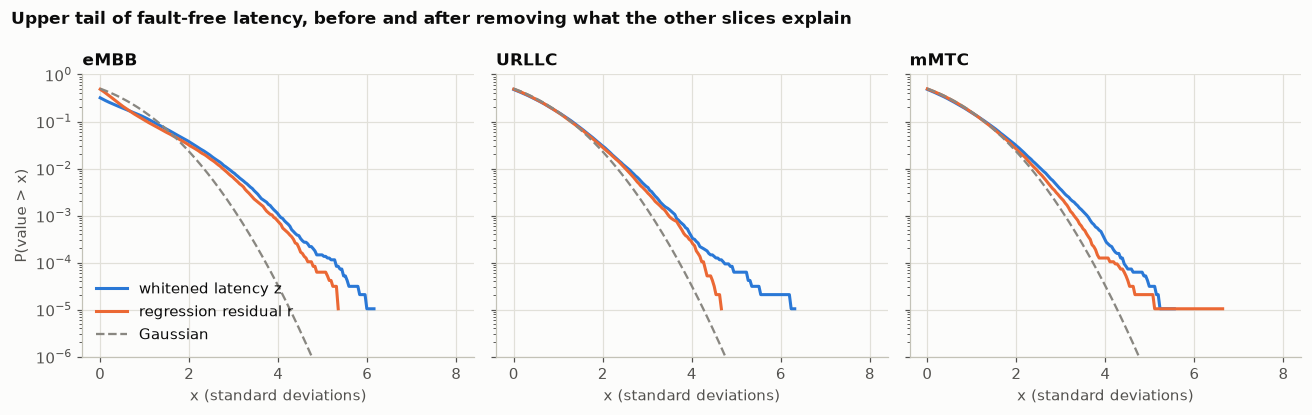

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
xs = np.linspace(0, 8, 200)
for ax, j in zip(axes, range(3)):
    for x, col, lab in [(flat[:, j], BLUE, "whitened latency z"), (Rcal.reshape(-1, 3)[:, j], ORANGE, "regression residual r")]:
        x = (x - x.mean()) / x.std()
        sv = np.array([(x > t).mean() for t in xs])
        ax.plot(xs, np.where(sv > 0, sv, np.nan), color=col, label=lab)
    ax.plot(xs, stats.norm.sf(xs), color=MUTED, ls="--", lw=1.5, label="Gaussian")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1)
    ax.set_title(SLICES[j]); ax.set_xlabel("x (standard deviations)")
axes[0].set_ylabel("P(value > x)")
axes[0].legend(loc="lower left")
fig.suptitle("Upper tail of fault-free latency, before and after removing what the other slices explain",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_tails")
plt.show()

**What T1 shows: the "heavy-tailed common factor" is only partly there**

- **The common mode is large but only mildly non-Gaussian.** It carries 70% of the variance (leading eigenvector about equal on all three slices), but its excess kurtosis is only 0.66.
- **The URLLC and mMTC latency streams are close to Gaussian, and $\Sigma^{-1}$ thins their tails only a little:** excess kurtosis 0.27 → 0.20 and 0.31 → 0.16, 99.9% quantile 3.63 → 3.48 and 3.59 → 3.29 sd.
- **eMBB is the heavy-tailed stream** (excess kurtosis 5.5), and regression adjustment does not change that.

So heavy-tail cancellation cannot be the main explanation of the 6–19× gain. The tests below find what is.

## T2. Threshold inflation

For each slice, calibrate a one-sided CUSUM ($k = 0.5$, up direction) to ARL 1000 on $z_j$ and on $r_j$, and compare with the i.i.d. Gaussian threshold for the same ARL (Siegmund). Inflation above the Gaussian value is the price of heavy tails and memory.

In [4]:
def siegmund_one_sided(h, k=0.5):
    D, b = -k, h + 1.166
    return (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D**2)
H_GAUSS = brentq(lambda h: siegmund_one_sided(h) - TARGET_ARL, 0.5, 50)

def one_sided():
    return CUSUMBank([[1.0]], [[1.0]])          # increment x - 1/2 on a single stream

H = {}
rows = []
for j, s in enumerate(SLICES):
    hz, _ = calibrate_threshold(one_sided(), Zcal[:, :, [j]], TARGET_ARL)
    hr, _ = calibrate_threshold(one_sided(), Rcal[:, :, [j]], TARGET_ARL)
    H[j] = (hz, hr)
    rows.append(dict(slice=s, h_gaussian=H_GAUSS, h_per_slice=hz, h_residual=hr,
                     inflation_per_slice=hz / H_GAUSS, inflation_residual=hr / H_GAUSS, threshold_factor=hz / hr))
thr = pd.DataFrame(rows)
thr.round(2)

,slice,h_gaussian,h_per_slice,h_residual,inflation_per_slice,inflation_residual,threshold_factor
0,eMBB,5.06,9.96,7.62,1.97,1.51,1.31
1,URLLC,5.06,7.14,3.53,1.41,0.70,2.02
2,mMTC,5.06,6.45,3.13,1.27,0.62,2.06


**What T2 shows: half of the explanation is a 2× lower threshold, with a puzzle**

- **The residual needs about half the threshold.** For URLLC and mMTC, the residual's CUSUM reaches ARL 1000 with a threshold 2.0× lower than the raw stream's (3.53 vs 7.14, and 3.13 vs 6.45).
- **The raw streams sit above the Gaussian value** (5.06), by 1.27–1.41×.
- **The residuals sit *below* it** (0.62–0.70×). Heavy tails cannot push a threshold below the Gaussian value, so something else is at work. T5 identifies it.

## T3 and T4. Does threshold factor × drift factor explain the speed-up, and does it vanish on Gaussian data?

**Faults:** the slice-local ones (URLLC surge, mMTC storm, URLLC weight misconfiguration) at strengths where the per-slice detector still detects, plus the shared capacity drop for contrast. The runs use the same seeds as notebooks 05–08, 32 runs each, with the fault at 10 s.

For each case we use the faulted slice $j$ and measure:
- **measured speed-up:** delay of the one-sided CUSUM on $z_j$ ÷ delay of the one on $r_j$, both at ARL 1000;
- **threshold factor** $h_z/h_r$ (from T2), and **drift factor** $\mu_r/\mu_z$, with $\mu$ the mean post-fault increment ($x - \tfrac12$);
- **Gaussian control (T4):** draw i.i.d. $\mathcal N(0, \Sigma)$ data, add the *measured* post-fault mean shift of $z$ from the same case, calibrate the same two detectors on Gaussian fault-free data to ARL 1000, and measure the speed-up there.

In [5]:
SCEN = load_fault_scenarios("../configs/faults.yaml", start_s=10.0)
ALL = list(SCEN)
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]          # index -> seed, as in notebook 05
CASES = [("urllc_surge", 0.1, 1), ("urllc_surge", 0.25, 1), ("mmtc_storm", 0.1, 2), ("mmtc_storm", 0.25, 2),
         ("urllc_weight_misconfig", 0.1, 1), ("urllc_weight_misconfig", 0.25, 1),
         ("capacity_drop", 0.25, 1), ("capacity_drop", 0.5, 1)]
NICE = {"urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm", "urllc_weight_misconfig": "URLLC weight misconfig.",
        "capacity_drop": "capacity drop (shared)"}

# Gaussian surrogate fault-free data and thresholds (same Sigma, i.i.d. over time)
rng = np.random.default_rng([SEED, 9])
Gcal = rng.multivariate_normal(np.zeros(3), Sigma, size=(32, 3000))
GR = residuals(Gcal)
HG = {j: (calibrate_threshold(one_sided(), Gcal[:, :, [j]], TARGET_ARL)[0],
          calibrate_threshold(one_sided(), GR[:, :, [j]], TARGET_ARL)[0]) for j in range(3)}

def mean_delay(det, Z, h, change):
    t, _ = first_alarms(det, Z, h)
    return summarize_delays(t, change, 300, 0.1)

rows = []
t0 = time.time()
for scen, s, j in CASES:
    i = ALL.index(scen)
    faults = [Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in SCEN[scen]]
    res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + STRENGTHS.index(s), faults=faults)
    Z = model.whiten(stream_array(res, LAT)); R = residuals(Z)
    nu = res.fault_window
    post = slice(nu + 5, None)
    hz, hr = H[j]
    dz = mean_delay(one_sided(), Z[:, :, [j]], hz, nu)
    dr = mean_delay(one_sided(), R[:, :, [j]], hr, nu)
    mu_z = Z[:, post, j].mean() - 0.5
    mu_r = R[:, post, j].mean() - 0.5
    # Gaussian control with the same measured mean shift of z (all three slices)
    shift = Z[:, post].mean(axis=(0, 1)) - Z[:, :nu].mean(axis=(0, 1))
    G = rng.multivariate_normal(np.zeros(3), Sigma, size=(32, 400)); G[:, nu:] += shift
    gz = mean_delay(one_sided(), G[:, :, [j]], HG[j][0], nu)
    gr = mean_delay(one_sided(), residuals(G)[:, :, [j]], HG[j][1], nu)
    rows.append(dict(case=f"{NICE[scen]}, s = {s:g}", slice=SLICES[j],
                     delay_z=dz["delay_mean_s"], delay_r=dr["delay_mean_s"],
                     detected_z=dz["detected"], detected_r=dr["detected"],
                     measured_speedup=dz["delay_mean_s"] / dr["delay_mean_s"],
                     threshold_factor=hz / hr, drift_factor=mu_r / mu_z if mu_z > 0 else np.nan,
                     gaussian_speedup=gz["delay_mean_s"] / gr["delay_mean_s"],
                     shift_z=shift[j]))
dec = pd.DataFrame(rows)
dec["predicted_speedup"] = dec.threshold_factor * dec.drift_factor
dec.to_csv(OUT / "decomposition.csv", index=False)
print(f"simulated and scored in {time.time() - t0:.0f} s")
dec.round(2)

simulated and scored in 50 s


,case,slice,delay_z,delay_r,detected_z,detected_r,measured_speedup,threshold_factor,drift_factor,gaussian_speedup,shift_z,predicted_speedup
0,"URLLC surge, s = 0.1",URLLC,9.05,1.95,0.97,1.00,4.63,2.02,NaN,2.06,0.39,NaN
1,"URLLC surge, s = 0.25",URLLC,1.00,0.18,1.00,1.00,5.53,2.02,1.74,1.68,1.10,3.51
2,"mMTC storm, s = 0.1",mMTC,8.91,2.25,0.97,1.00,3.96,2.06,NaN,2.74,0.29,NaN
3,"mMTC storm, s = 0.25",mMTC,1.53,0.12,1.00,1.00,12.55,2.06,2.15,1.47,0.83,4.41
4,"URLLC weight misconfig., s = 0.1",URLLC,5.21,0.51,1.00,1.00,10.23,2.02,11.06,2.45,0.60,22.36
5,"URLLC weight misconfig., s = 0.25",URLLC,0.49,0.10,1.00,1.00,4.86,2.02,1.99,1.74,1.64,4.03
6,"capacity drop (shared), s = 0.25",URLLC,14.88,15.82,0.86,0.77,0.94,2.02,NaN,0.54,0.32,NaN
7,"capacity drop (shared), s = 0.5",URLLC,3.45,5.69,1.00,1.00,0.61,2.02,-1.00,0.30,0.67,-2.02


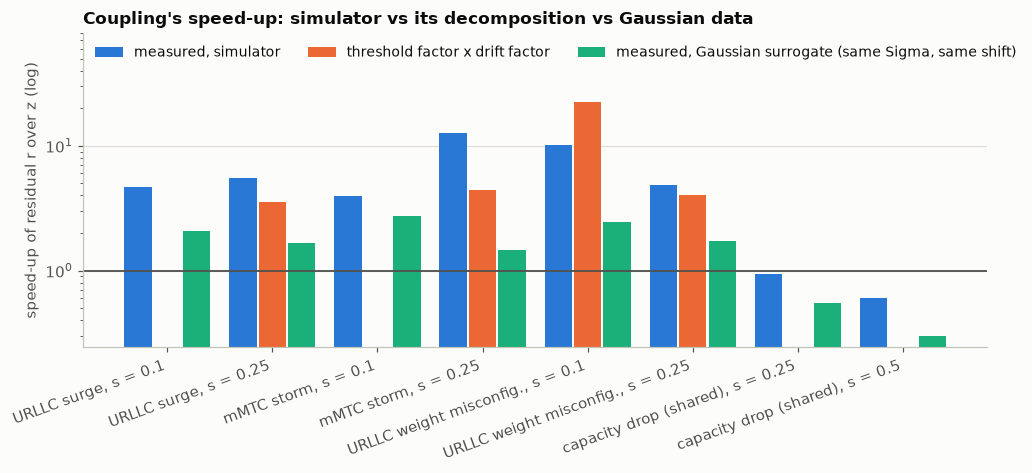

In [6]:
local = dec[~dec.case.str.startswith("capacity")]
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(dec))
w = 0.26
ax.bar(x - w - 0.02, dec.measured_speedup, width=w, color=BLUE, label="measured, simulator")
ax.bar(x, dec.predicted_speedup, width=w, color=ORANGE, label="threshold factor x drift factor")
ax.bar(x + w + 0.02, dec.gaussian_speedup, width=w, color=AQUA, label="measured, Gaussian surrogate (same Sigma, same shift)")
ax.axhline(1, color=INK2, lw=1.2)
ax.set_xticks(x, dec.case, rotation=20, ha="right")
ax.grid(axis="x", visible=False)
ax.set_yscale("log")
ax.set_ylabel("speed-up of residual r over z (log)")
ax.set_title("Coupling's speed-up: simulator vs its decomposition vs Gaussian data")
ax.set_ylim(top=80)
ax.legend(loc="upper left", fontsize=9, ncol=3)
fig.tight_layout()
save_fig(fig, "fig2_decomposition")
plt.show()

**What T3 and T4 show**

- **The extra gain is real, and it comes from the noise, not the signal.** On the simulator, the residual detector is 4.0–12.6× faster than the per-slice one on the local faults. On Gaussian data with the *same* $\Sigma$ and the *same* fault shift, it is only 1.5–2.7× faster, close to first-order theory. The shift is identical in both, so the difference is caused entirely by the structure of the fault-free noise.
- **Shared faults: coupling hurts,** in both settings (capacity drop: 0.61–0.94× on the simulator, 0.30–0.54× on Gaussian data), as predicted.
- **The decomposition threshold factor × drift factor is only a rough guide.** For weak faults the per-slice drift $\mu_z$ is negative (the shift is below the reference value $k = \tfrac12$), so delay ≈ $h/\mu$ does not apply. Where it does apply, it predicts 3.5–4.4× against measured 5.5–12.6×. Threshold reduction explains part of the gain; the rest comes from smaller noise fluctuations around the drift (T5–T6).

## T5. Tails or memory? A shuffle test

T2 found residual thresholds *below* the i.i.d. Gaussian value. Heavy tails alone cannot do that; serial dependence can, for example negative autocorrelation in the residuals.

To separate the two, we **shuffle the windows in time** within each run, jointly for all three slices. This keeps every marginal distribution (the tails) and the cross-slice dependence, and destroys memory. If the threshold factor survives shuffling, the tails drive it; if it collapses towards 1, memory does.

In [7]:
def acf1(X, lag=1):
    Xc = X - X.mean(axis=1, keepdims=True)
    return (Xc[:, lag:] * Xc[:, :-lag]).sum() / (Xc**2).sum()

shuf_rng = np.random.default_rng([SEED, 5])
perm = np.stack([shuf_rng.permutation(Zcal.shape[1]) for _ in range(Zcal.shape[0])])
Zsh = np.take_along_axis(Zcal, perm[:, :, None], axis=1)
Rsh = residuals(Zsh)
rows = []
for j, s in enumerate(SLICES):
    hz_s, _ = calibrate_threshold(one_sided(), Zsh[:, :, [j]], TARGET_ARL)
    hr_s, _ = calibrate_threshold(one_sided(), Rsh[:, :, [j]], TARGET_ARL)
    rows.append(dict(slice=s, acf1_z=acf1(Zcal[:, :, j]), acf1_r=acf1(Rcal[:, :, j]),
                     acf2_r=acf1(Rcal[:, :, j], 2),
                     threshold_factor=H[j][0] / H[j][1], threshold_factor_shuffled=hz_s / hr_s,
                     h_z_shuffled=hz_s, h_r_shuffled=hr_s, h_gaussian=H_GAUSS))
mem = pd.DataFrame(rows)

def long_run_var(X, L=50):
    # Bartlett-weighted sum of autocovariances: the noise power at frequency zero, per unit marginal variance
    Xc = X - X.mean(axis=1, keepdims=True)
    g0 = (Xc**2).mean()
    s = g0 + 2 * sum((1 - l / (L + 1)) * (Xc[:, l:] * Xc[:, :-l]).mean() for l in range(1, L + 1))
    return s / g0
mem["lrv_z"] = [long_run_var(Zcal[:, :, j]) for j in range(3)]
mem["lrv_r"] = [long_run_var(Rcal[:, :, j]) for j in range(3)]
mem["lrv_ratio"] = mem.lrv_z / mem.lrv_r      # predicted threshold factor if h scales with long-run variance
mem.to_csv(OUT / "shuffle_test.csv", index=False)
mem.round(3)

,slice,acf1_z,acf1_r,acf2_r,threshold_factor,threshold_factor_shuffled,h_z_shuffled,h_r_shuffled,h_gaussian,lrv_z,lrv_r,lrv_ratio
0,eMBB,0.188,0.057,-0.147,1.306,1.066,5.562,5.219,5.063,0.769,0.397,1.937
1,URLLC,-0.048,-0.393,0.020,2.021,1.041,5.312,5.102,5.063,1.390,0.441,3.149
2,mMTC,0.033,-0.313,-0.061,2.056,0.997,5.461,5.477,5.063,1.104,0.161,6.839


**What T5 shows: it is memory, not tails**

- **Shuffling removes the threshold reduction completely.** Once the windows are shuffled in time (marginal tails and cross-slice dependence kept, memory destroyed), the threshold factor drops from 2.0 to **1.0** for URLLC and mMTC. All shuffled thresholds sit at the Gaussian value (5.1–5.5).
- **The cause is the residuals' negative autocorrelation.** Lag-1 autocorrelation is −0.39 for URLLC and −0.31 for mMTC, against ≈ 0 for the per-stream whitened inputs. Noise that keeps reversing itself makes short CUSUM excursions, while a sustained fault does not reverse.
- **Equivalently, the residuals carry far less low-frequency noise.** Their long-run variance (noise power at frequency zero, relative to the marginal variance) is 0.44 and 0.16, against 1.39 and 1.10 for the per-slice streams.

## T6. The coupling gain at zero frequency

A sustained fault is a DC signal. For it, the relevant cross-slice correlation is not the instantaneous one, but the correlation of the slow, low-frequency parts of the noise: the squared multiple **coherence at frequency zero**. Its matrix is the **long-run covariance** $\Sigma_{LR} = \sum_{\ell} \operatorname{Cov}(z_t, z_{t-\ell})$, the cross-spectral density at frequency 0 (Bartlett-weighted, 50 lags).

The first-order gain of a coupled detector for a fault in slice $j$ alone is then $\Sigma_{LR,jj}\,(\Sigma_{LR}^{-1})_{jj} = 1/(1 - R^2_{j,\text{DC}})$, instead of the instantaneous $\Sigma_{jj}(\Sigma^{-1})_{jj} = 1/(1-R_j^2)$.

In [8]:
Zc = Zcal - Zcal.mean(axis=1, keepdims=True)
def cross_cov(l):
    n = Zc.shape[0] * (Zc.shape[1] - l)
    return np.einsum("rti,rtj->ij", Zc[:, l:], Zc[:, :Zc.shape[1] - l]) / n
S0 = cross_cov(0)
L_LAGS = 50
SLR = S0.copy()
for l in range(1, L_LAGS + 1):
    G = cross_cov(l)
    SLR += (1 - l / (L_LAGS + 1)) * (G + G.T)
gain_inst = np.diag(S0) * np.diag(np.linalg.inv(S0))
gain_dc = np.diag(SLR) * np.diag(np.linalg.inv(SLR))
meas = dec[~dec.case.str.startswith("capacity")].groupby("slice").measured_speedup.agg(["min", "max"])
dcg = pd.DataFrame({"slice": SLICES, "instantaneous_gain": gain_inst, "zero_frequency_gain": gain_dc})
dcg = dcg.join(meas, on="slice").rename(columns={"min": "measured_min", "max": "measured_max"})
dcg.to_csv(OUT / "dc_gain.csv", index=False)
dcg.round(2)

,slice,instantaneous_gain,zero_frequency_gain,measured_min,measured_max
0,eMBB,1.33,2.71,NaN,NaN
1,URLLC,2.08,21.11,4.63,10.23
2,mMTC,2.27,22.36,3.96,12.55


**What T6 shows: the gain is governed by coherence at zero frequency**

- **At zero frequency the predicted gain is about ten times larger.** The instantaneous gain is $1/(1 - R^2) \approx 2.1$–$2.3$ for URLLC and mMTC: the "Gaussian first-order" figure. At frequency zero it is **about 21–22**, because the slow shared noise (eMBB bursts and capacity drift, lasting hundreds of ms) makes the slices far more coherent at low frequency than at lag 0.
- **The measured speed-ups (4–12.6×) lie between the two**, as expected. Our bank uses the instantaneous $\Sigma^{-1}$, which is not the filter that is optimal for a DC signal.
- **This also makes a testable prediction:** a coupled detector built on the long-run covariance $\Sigma_{LR}$ should be faster still.

In [9]:
# Export tables and key numbers for report/main.tex
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
tab = tails.assign(share_of_variance=tails.share_of_variance.map(lambda v: "" if pd.isna(v) else f"{100 * v:.0f}\\%"),
                   excess_kurtosis=tails.excess_kurtosis.map(f2), skewness=tails.skewness.map(f2), q999=tails.q999.map(f2))
tab.columns = ["series", "variance share", "excess kurtosis", "skewness", "99.9\\% quantile (sd)"]
save_tex_table(tab, "tails", "lrrrr")

tab = dec[["case", "slice", "delay_z", "delay_r", "measured_speedup", "threshold_factor", "drift_factor",
           "predicted_speedup", "gaussian_speedup"]].copy()
for c in tab.columns[2:]:
    tab[c] = tab[c].map(f2)
tab.columns = ["case", "slice", "delay $z$ (s)", "delay $r$ (s)", "speed-up", "threshold f.", "drift f.",
               "predicted", "Gaussian"]
save_tex_table(tab, "decomposition", "llrrrrrrr")

T = tails.set_index("series")
L = local
save_tex_numbers({
    "TailCommonKurt": f"{T.loc['common mode (leading eigenvector)', 'excess_kurtosis']:.1f}",
    "TailCommonShare": f"{100 * T.loc['common mode (leading eigenvector)', 'share_of_variance']:.0f}",
    "TailUrllcZKurt": f"{T.loc['URLLC: whitened latency z', 'excess_kurtosis']:.1f}",
    "TailUrllcRKurt": f"{T.loc['URLLC: regression residual r', 'excess_kurtosis']:.1f}",
    "TailMmtcZKurt": f"{T.loc['mMTC: whitened latency z', 'excess_kurtosis']:.1f}",
    "TailMmtcRKurt": f"{T.loc['mMTC: regression residual r', 'excess_kurtosis']:.1f}",
    "ThrFactorUrllc": f"{thr.set_index('slice').loc['URLLC', 'threshold_factor']:.2f}",
    "ThrFactorMmtc": f"{thr.set_index('slice').loc['mMTC', 'threshold_factor']:.2f}",
    "HGauss": f"{H_GAUSS:.2f}",
    "SpeedLocalMin": f"{L.measured_speedup.min():.1f}", "SpeedLocalMax": f"{L.measured_speedup.max():.1f}",
    "GaussLocalMin": f"{L.gaussian_speedup.min():.1f}", "GaussLocalMax": f"{L.gaussian_speedup.max():.1f}",
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("09_*")))

exported: ['09_decomposition.tex', '09_numbers.tex', '09_tails.tex']


## Summary

- **The "tail-cancellation" explanation, which our own analysis and the external review proposed, is not supported.** The common mode is only mildly non-Gaussian, and the coupled detector's lower threshold disappears once memory is removed by shuffling.
- **The mechanism is low-frequency common-mode cancellation.** Slices share *slow* noise (eMBB bursts, capacity drift), which per-stream whitening cannot remove and which dominates what a CUSUM accumulates. $\Sigma^{-1}$ across slices removes most of it, leaving residuals with negatively autocorrelated, low-power low-frequency noise.
- **The right theory is the coupling gain at zero frequency.** It is $1/(1 - R^2_{\text{DC}})$, built from the long-run (zero-frequency) covariance, not the instantaneous one. It is about 21–22 here against the instantaneous 2.1–2.3, and the measured 4–12.6× lies between the two.
- **This is the frequency-domain analogue of common-mode rejection in signals, and a sharper research claim than tail cancellation.** Before calling it novel, check the prior art on change detection with long-run covariance (econometric change-point tests use it routinely).
- **Next experiment:** a coupled bank using $\Sigma_{LR}^{-1}$, which this theory predicts should be faster still. Also, a fairer per-slice baseline with richer per-stream whitening, to measure how much of the gain survives.